# Evaluasi & Pembuktian Fitur Unik Model FER

Notebook ini digunakan khusus untuk melakukan evaluasi mendalam serta pembuktian terhadap dua fitur unik yang diimplementasikan:
1. **Fitur 1**: *Soft Voting Ensemble* & *Confidence Thresholding* (dengan batas $\tau = 0.5$).
2. **Fitur 2**: Eksperimen perbandingan *Selective Fine-Tuning* ResNet50 (Top-30 Layer vs Backbone Beku).

## STEP 1: Setup Lingkungan, Load Dataset, dan Inisialisasi Model

Pada tahap ini, kita akan:
- Melakukan mounting ke Google Drive.
- Mengunduh dan mengekstrak dataset FER.
- Mendefinisikan arsitektur kedua model utama (`AdvancedResidualFERModel` dan `OOPResNet50FERModel`).
- Memuat bobot (*weights*) terbaik hasil `UTS_Modip.ipynb` dari Google Drive (file yang sama dengan yang dipakai aplikasi).

**Penting:** gunakan runtime **GPU (T4)**. STEP 3 melatih dua model ResNet50 dan akan sangat lama jika memakai CPU.

In [1]:
# =========================================================================
# STEP 1: SETUP & LOAD DATASET & LOAD BOBOT TERBAIK
# =========================================================================
from google.colab import drive
drive.mount('/content/drive')

import os
import zipfile
import gdown
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from sklearn.utils.class_weight import compute_class_weight

# --- CONFIG & PATH ---
zip_path_drive = '/content/drive/MyDrive/ML DL/DL/archive.zip'
shared_link_or_id = 'https://drive.google.com/file/d/1r5IwzD4g07gEl1SCFQDjc9PUCD1_d3Lb/view?usp=sharing'
extract_path = '/content/dataset'
output_zip_local = '/content/archive.zip'
drive_dest_folder = '/content/drive/MyDrive/ML DL/DL/UTS/Output'

def get_gdrive_id(link_or_id):
    if 'drive.google.com' in link_or_id:
        match = re.search(r'/d/([^/]+)', link_or_id)
        if match:
            return match.group(1)
    return link_or_id

file_id_shared = get_gdrive_id(shared_link_or_id)

if not os.path.exists(extract_path):
    if os.path.exists(zip_path_drive):
        with zipfile.ZipFile(zip_path_drive, 'r') as zip_ref:
            zip_ref.extractall(extract_path)
    elif file_id_shared and file_id_shared != 'MASUKKAN_FILE_ID_DISINI':
        url = f'https://drive.google.com/uc?id={file_id_shared}'
        gdown.download(url, output_zip_local, quiet=False)
        if os.path.exists(output_zip_local):
            with zipfile.ZipFile(output_zip_local, 'r') as zip_ref:
                zip_ref.extractall(extract_path)

# Data Generator Validation (Grayscale 48x48)
IMG_HEIGHT, IMG_WIDTH, BATCH_SIZE = 48, 48, 64
base_dir = extract_path
subdirs = os.listdir(base_dir)
test_dir = os.path.join(base_dir, 'test') if 'test' in subdirs else (os.path.join(base_dir, 'validation') if 'validation' in subdirs else base_dir)

val_datagen_gray = ImageDataGenerator(rescale=1./255)
val_gen_gray = val_datagen_gray.flow_from_directory(
    test_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    color_mode='grayscale',
    class_mode='categorical',
    shuffle=False
)
num_classes = len(val_gen_gray.class_indices)
class_labels = list(val_gen_gray.class_indices.keys())

Mounted at /content/drive


Downloading...
From (original): https://drive.google.com/uc?id=1r5IwzD4g07gEl1SCFQDjc9PUCD1_d3Lb
From (redirected): https://drive.google.com/uc?id=1r5IwzD4g07gEl1SCFQDjc9PUCD1_d3Lb&confirm=t&uuid=f1f605da-c304-4542-96a8-9ffae873e10c
To: /content/archive.zip
100%|██████████| 63.3M/63.3M [00:00<00:00, 128MB/s]


Found 7178 images belonging to 7 classes.



### Definisi Arsitektur Model & Memuat Bobot Model Terlatih

In [2]:
# --- DEFINISI ARSITEKTUR MODEL 1 & 2 ---
class ResidualBlock(layers.Layer):
    def __init__(self, filters, stride=1, **kwargs):
        super(ResidualBlock, self).__init__(**kwargs)
        self.filters = filters
        self.stride = stride
        self.conv1 = layers.Conv2D(filters, (3, 3), strides=stride, padding='same', use_bias=False)
        self.bn1 = layers.BatchNormalization()
        self.conv2 = layers.Conv2D(filters, (3, 3), strides=1, padding='same', use_bias=False)
        self.bn2 = layers.BatchNormalization()
        if stride != 1:
            self.shortcut = tf.keras.Sequential([
                layers.Conv2D(filters, (1, 1), strides=stride, padding='same', use_bias=False),
                layers.BatchNormalization()
            ])
        else:
            self.shortcut = lambda x, training=False: x

    def call(self, inputs, training=False):
        shortcut = self.shortcut(inputs, training=training)
        x = self.conv1(inputs)
        x = self.bn1(x, training=training)
        x = tf.nn.relu(x)
        x = self.conv2(x)
        x = self.bn2(x, training=training)
        x = layers.add([x, shortcut])
        return tf.nn.relu(x)

    def get_config(self):
        config = super(ResidualBlock, self).get_config()
        config.update({"filters": self.filters, "stride": self.stride})
        return config

class AdvancedResidualFERModel(Model):
    def __init__(self, num_classes, **kwargs):
        super(AdvancedResidualFERModel, self).__init__(**kwargs)
        self.init_conv = layers.Conv2D(64, (3, 3), padding='same', activation='relu')
        self.init_bn = layers.BatchNormalization()
        self.res_block1 = ResidualBlock(64, stride=1)
        self.pool1 = layers.MaxPooling2D(2, 2)
        self.drop1 = layers.Dropout(0.3)
        self.res_block2 = ResidualBlock(128, stride=2)
        self.pool2 = layers.MaxPooling2D(2, 2)
        self.drop2 = layers.Dropout(0.3)
        self.res_block3 = ResidualBlock(256, stride=2)
        self.gap = layers.GlobalAveragePooling2D()
        self.dense = layers.Dense(256, activation='relu')
        self.bn_dense = layers.BatchNormalization()
        self.drop_dense = layers.Dropout(0.5)
        self.out = layers.Dense(num_classes, activation='softmax')

    def call(self, inputs, training=False):
        x = self.init_conv(inputs)
        x = self.init_bn(x, training=training)
        x = self.res_block1(x, training=training)
        x = self.pool1(x)
        x = self.drop1(x, training=training)
        x = self.res_block2(x, training=training)
        x = self.pool2(x)
        x = self.drop2(x, training=training)
        x = self.res_block3(x, training=training)
        x = self.gap(x)
        x = self.dense(x)
        x = self.bn_dense(x, training=training)
        x = self.drop_dense(x, training=training)
        return self.out(x)

NEW_IMG_SIZE = 96
class OOPResNet50FERModel(Model):
    def __init__(self, num_classes, **kwargs):
        super(OOPResNet50FERModel, self).__init__(**kwargs)
        self.base_model = ResNet50(input_shape=(NEW_IMG_SIZE, NEW_IMG_SIZE, 3), include_top=False, weights='imagenet')
        self.base_model.trainable = True
        for layer in self.base_model.layers[:-30]:
            layer.trainable = False
        self.gap = layers.GlobalAveragePooling2D()
        self.dense = layers.Dense(256, activation='relu')
        self.bn = layers.BatchNormalization()
        self.dropout = layers.Dropout(0.5)
        self.out = layers.Dense(num_classes, activation='softmax')

    def call(self, inputs, training=False):
        x = tf.image.grayscale_to_rgb(inputs)
        x = tf.image.resize(x, (NEW_IMG_SIZE, NEW_IMG_SIZE))
        x = x * 255.0
        x = tf.keras.applications.resnet50.preprocess_input(x)
        x = self.base_model(x, training=training)
        x = self.gap(x)
        x = self.dense(x)
        x = self.bn(x, training=training)
        x = self.dropout(x, training=training)
        return self.out(x)

# Build & Load Weights
vanilla_model = AdvancedResidualFERModel(num_classes=num_classes)
_ = vanilla_model(tf.zeros((1, IMG_HEIGHT, IMG_WIDTH, 1)))
vanilla_model.load_weights(os.path.join(drive_dest_folder, 'best_vanilla_modified_fer_model.weights.h5'))

resnet_model = OOPResNet50FERModel(num_classes=num_classes)
_ = resnet_model(tf.zeros((1, IMG_HEIGHT, IMG_WIDTH, 1)))
resnet_model.load_weights(os.path.join(drive_dest_folder, 'best_resnet_modified_fer.weights.h5'))

print("✓ Model 1 & Model 2 berhasil di-build dan bobot dimuat dari Google Drive!")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
✓ Model 1 & Model 2 berhasil di-build dan bobot dimuat dari Google Drive!


## STEP 2: Pembuktian Fitur Unik 1 — Ensemble & Ambang Keyakinan (Confidence Thresholding)

Di sini kita membuktikan efektivitas penggabungan prediksi kedua model menggunakan rumus **Soft Voting Ensemble** (merata-ratakan probabilitas output).

Selain itu, kita menguji skenario **Confidence Thresholding ($\tau = 0.5$)**, di mana model hanya memberikan keputusan klasifikasi jika tingkat keyakinannya di atas ambang batas tersebut. Kita juga akan membuat grafik kurva trade-off akurasi vs persentase wajah yang dijawab.


  PEMBUKTIAN FITUR UNIK 1: ENSEMBLE & CONFIDENCE THRESHOLDING
113/113 ━━━━━━━━━━━━━━━━━━━━ 9s 43ms/step
113/113 ━━━━━━━━━━━━━━━━━━━━ 21s 103ms/step


,Accuracy (Tanpa Threshold),Macro F1,Citra Yakin (>= 0.5),Accuracy (Hanya yang Yakin),Jumlah Salah (Tanpa Ambang),Jumlah Salah (Dengan Ambang)
Model,,,,,,
Custom Residual CNN,0.513,0.441,0.444,0.705,3496,940
ResNet50,0.617,0.597,0.751,0.702,2747,1609
Ensemble (Custom + ResNet50),0.627,0.590,0.545,0.796,2679,798


Hanya salah di Custom   : 1462
Hanya salah di ResNet50 : 713
Salah di keduanya       : 2034

Laporan Klasifikasi (Ensemble, tanpa ambang):
              precision    recall  f1-score   support

       angry       0.54      0.55      0.55       958
     disgust       0.38      0.76      0.50       111
        fear       0.58      0.32      0.41      1024
       happy       0.87      0.80      0.83      1774
     neutral       0.52      0.73      0.61      1233
         sad       0.54      0.43      0.48      1247
    surprise       0.67      0.84      0.75       831

    accuracy                           0.63      7178
   macro avg       0.59      0.63      0.59      7178
weighted avg       0.64      0.63      0.62      7178



,Tau,Citra Dijawab (%),Akurasi (%)
0,0.0,100.0,62.7
1,0.3,94.5,64.8
2,0.4,75.6,71.6
3,0.5,54.5,79.6
4,0.6,37.8,86.3
5,0.7,26.4,91.4
6,0.8,18.3,94.5
7,0.9,11.4,96.7


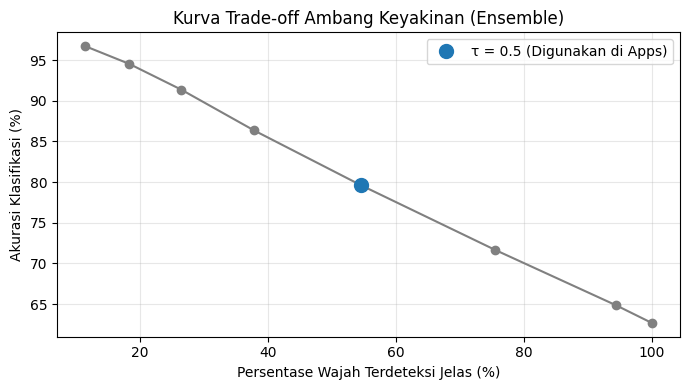

In [3]:
# =========================================================================
# STEP 2: FITUR UNIK 1 — PEMBUKTIAN ENSEMBLE & AMBANG KEYAKINAN (tau = 0.5)
# =========================================================================
print("\n" + "="*60)
print("  PEMBUKTIAN FITUR UNIK 1: ENSEMBLE & CONFIDENCE THRESHOLDING")
print("="*60)

val_gen_gray.reset()
prob_vanilla = vanilla_model.predict(val_gen_gray, verbose=1)
val_gen_gray.reset()
prob_resnet = resnet_model.predict(val_gen_gray, verbose=1)

# Formula Soft Voting Ensemble (Rata-rata Probabilitas)
prob_ensemble = (prob_vanilla + prob_resnet) / 2
y_true = val_gen_gray.classes

TAU = 0.5
hasil = []
for nama, prob in [('Custom Residual CNN', prob_vanilla),
                   ('ResNet50', prob_resnet),
                   ('Ensemble (Custom + ResNet50)', prob_ensemble)]:
    y_pred = prob.argmax(axis=1)
    benar = (y_pred == y_true)
    dijawab = (prob.max(axis=1) >= TAU)
    hasil.append({
        'Model': nama,
        'Accuracy (Tanpa Threshold)': benar.mean(),
        'Macro F1': f1_score(y_true, y_pred, average='macro'),
        'Citra Yakin (>= 0.5)': dijawab.mean(),
        'Accuracy (Hanya yang Yakin)': benar[dijawab].mean(),
        'Jumlah Salah (Tanpa Ambang)': (~benar).sum(),
        'Jumlah Salah (Dengan Ambang)': (~benar[dijawab]).sum(),
    })

tabel_ensemble = pd.DataFrame(hasil).set_index('Model')
display(tabel_ensemble.round(3))

# Apakah kedua model membuat kesalahan yang berbeda? (alasan ensemble bisa membantu)
salah_vanilla = prob_vanilla.argmax(axis=1) != y_true
salah_resnet = prob_resnet.argmax(axis=1) != y_true
print("Hanya salah di Custom   :", (salah_vanilla & ~salah_resnet).sum())
print("Hanya salah di ResNet50 :", (~salah_vanilla & salah_resnet).sum())
print("Salah di keduanya       :", (salah_vanilla & salah_resnet).sum())

print("\nLaporan Klasifikasi (Ensemble, tanpa ambang):")
print(classification_report(y_true, prob_ensemble.argmax(axis=1), target_names=class_labels))

# Kurva Perbandingan Ambang Keyakinan (Tau)
yakin = prob_ensemble.max(axis=1)
benar = prob_ensemble.argmax(axis=1) == y_true

baris = []
for t in [0, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    baris.append({
        'Tau': t,
        'Citra Dijawab (%)': (yakin >= t).mean() * 100,
        'Akurasi (%)': benar[yakin >= t].mean() * 100
    })
kurva = pd.DataFrame(baris)
display(kurva.round(1))

plt.figure(figsize=(7, 4))
plt.plot(kurva['Citra Dijawab (%)'], kurva['Akurasi (%)'], 'o-', color='gray')
titik = kurva[kurva['Tau'] == TAU]
plt.plot(titik['Citra Dijawab (%)'], titik['Akurasi (%)'], 'o', markersize=10, color='tab:blue', label='τ = 0.5 (Digunakan di Apps)')
plt.xlabel('Persentase Wajah Terdeteksi Jelas (%)')
plt.ylabel('Akurasi Klasifikasi (%)')
plt.title('Kurva Trade-off Ambang Keyakinan (Ensemble)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## STEP 3: Pembuktian Fitur Unik 2 — Backbone Beku vs Top-30 Fine-Tuning

Pada langkah ini, kita melakukan eksperimen pelatihan ulang dengan dua skenario untuk membuktikan bahwa membuka 30 layer teratas ResNet50 (*Top-30 Fine-Tuning*) memberikan performa yang jauh lebih optimal dibanding membekukan total seluruh parameter backbone (*Full Frozen*).

In [4]:
# =========================================================================
# STEP 3: FITUR UNIK 2 — PEMBUKTIAN SELECTIVE FINE-TUNING RESNET50
# =========================================================================
print("\n" + "="*60)
print("  PEMBUKTIAN FITUR UNIK 2: BACKBONE BEKU VS TOP-30 FINE-TUNING")
print("="*60)

import time
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

train_datagen_gray = ImageDataGenerator(
    rescale=1./255, rotation_range=15, width_shift_range=0.15,
    height_shift_range=0.15, shear_range=0.15, zoom_range=0.15, horizontal_flip=True
)
train_gen_gray = train_datagen_gray.flow_from_directory(
    os.path.join(base_dir, 'train') if 'train' in subdirs else base_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, color_mode='grayscale', class_mode='categorical'
)

indeks_kelas = np.unique(train_gen_gray.classes)
bobot = compute_class_weight(class_weight='balanced', classes=indeks_kelas, y=train_gen_gray.classes)
class_weights_dict = dict(zip(indeks_kelas, bobot))

def latih_resnet_eksperimen(skenario):
    tf.keras.utils.set_random_seed(42)
    model = OOPResNet50FERModel(num_classes=num_classes)
    if skenario == 'beku':
        model.base_model.trainable = False
    _ = model(tf.zeros((1, IMG_HEIGHT, IMG_WIDTH, 1)))
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4), loss='categorical_crossentropy', metrics=['accuracy'])

    jumlah_dilatih = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
    print(f"\n--- Skenario '{skenario}': {jumlah_dilatih:,} parameter dilatih ---")

    callbacks = [
        EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, min_lr=1e-6, verbose=1),
    ]
    mulai = time.time()
    history = model.fit(train_gen_gray, epochs=20, validation_data=val_gen_gray, class_weight=class_weights_dict, callbacks=callbacks, verbose=2)
    menit = (time.time() - mulai) / 60
    return model, history, menit, jumlah_dilatih

resnet_beku, history_beku, menit_beku, param_beku = latih_resnet_eksperimen('beku')
resnet_top30, history_top30, menit_top30, param_top30 = latih_resnet_eksperimen('top30')


  PEMBUKTIAN FITUR UNIK 2: BACKBONE BEKU VS TOP-30 FINE-TUNING
Found 28709 images belonging to 7 classes.

--- Skenario 'beku': 526,855 parameter dilatih ---
Epoch 1/20
449/449 - 51s - 115ms/step - accuracy: 0.2598 - loss: 2.3696 - val_accuracy: 0.4001 - val_loss: 1.6942 - learning_rate: 1.0000e-04
Epoch 2/20
449/449 - 25s - 55ms/step - accuracy: 0.2966 - loss: 2.0744 - val_accuracy: 0.4107 - val_loss: 1.6565 - learning_rate: 1.0000e-04
Epoch 3/20
449/449 - 25s - 55ms/step - accuracy: 0.3177 - loss: 1.9507 - val_accuracy: 0.4150 - val_loss: 1.6160 - learning_rate: 1.0000e-04
Epoch 4/20
449/449 - 25s - 56ms/step - accuracy: 0.3338 - loss: 1.8570 - val_accuracy: 0.4430 - val_loss: 1.5263 - learning_rate: 1.0000e-04
Epoch 5/20
449/449 - 25s - 55ms/step - accuracy: 0.3446 - loss: 1.7889 - val_accuracy: 0.4401 - val_loss: 1.5069 - learning_rate: 1.0000e-04
Epoch 6/20
449/449 - 25s - 55ms/step - accuracy: 0.3581 - loss: 1.7227 - val_accuracy: 0.4635 - val_loss: 1.4537 - learning_rate: 1.000

### Analisis Hasil & Visualisasi Hasil Eksperimen Fitur 2

Kita bandingkan performa metrik akhir serta visualisasi grafik *Loss* dan *Accuracy* dari kedua skenario untuk membuktikan keunggulan *Fine-Tuning* selektif.


Laporan Klasifikasi (Backbone Full Frozen (Beku)):
              precision    recall  f1-score   support

       angry       0.35      0.31      0.33       958
     disgust       0.11      0.63      0.19       111
        fear       0.34      0.18      0.24      1024
       happy       0.68      0.67      0.67      1774
     neutral       0.43      0.49      0.46      1233
         sad       0.46      0.31      0.37      1247
    surprise       0.54      0.74      0.62       831

    accuracy                           0.47      7178
   macro avg       0.41      0.48      0.41      7178
weighted avg       0.48      0.47      0.46      7178


Laporan Klasifikasi (Top-30 Fine-Tuning (Model Utama)):
              precision    recall  f1-score   support

       angry       0.50      0.55      0.52       958
     disgust       0.44      0.71      0.55       111
        fear       0.52      0.35      0.42      1024
       happy       0.84      0.77      0.80      1774
     neutral       0.50

,Parameter Dilatih,Accuracy Test,Macro F1,Train Acc (Epoch Terakhir),Epoch Berjalan,Waktu Train (Menit)
Skenario,,,,,,
Backbone Full Frozen (Beku),526855,0.467,0.411,0.398,20,8.7
Top-30 Fine-Tuning (Model Utama),14977031,0.607,0.582,0.620,20,9.2


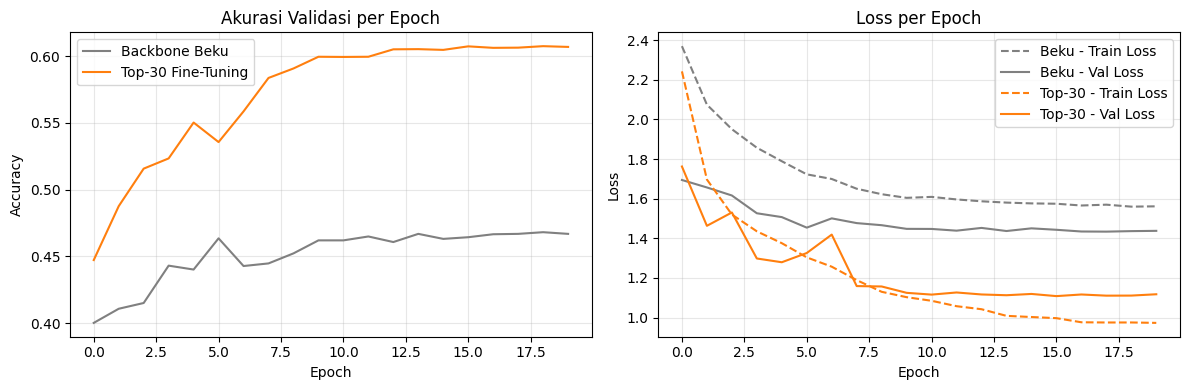

In [5]:
hasil_exp = []
for nama, model, history, menit, param in [
        ('Backbone Full Frozen (Beku)', resnet_beku, history_beku, menit_beku, param_beku),
        ('Top-30 Fine-Tuning (Model Utama)', resnet_top30, history_top30, menit_top30, param_top30)]:
    val_gen_gray.reset()
    y_pred = np.argmax(model.predict(val_gen_gray, verbose=0), axis=1)
    print(f"\nLaporan Klasifikasi ({nama}):")
    print(classification_report(y_true, y_pred, target_names=class_labels))
    hasil_exp.append({
        'Skenario': nama,
        'Parameter Dilatih': param,
        'Accuracy Test': accuracy_score(y_true, y_pred),
        'Macro F1': f1_score(y_true, y_pred, average='macro'),
        'Train Acc (Epoch Terakhir)': history.history['accuracy'][-1],
        'Epoch Berjalan': len(history.history['loss']),
        'Waktu Train (Menit)': round(menit, 1),
    })

display(pd.DataFrame(hasil_exp).set_index('Skenario').round(3))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_beku.history['val_accuracy'], label='Backbone Beku', color='gray')
plt.plot(history_top30.history['val_accuracy'], label='Top-30 Fine-Tuning', color='tab:orange')
plt.title('Akurasi Validasi per Epoch')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history_beku.history['loss'], '--', color='gray', label='Beku - Train Loss')
plt.plot(history_beku.history['val_loss'], color='gray', label='Beku - Val Loss')
plt.plot(history_top30.history['loss'], '--', color='tab:orange', label='Top-30 - Train Loss')
plt.plot(history_top30.history['val_loss'], color='tab:orange', label='Top-30 - Val Loss')
plt.title('Loss per Epoch')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()